In [1]:
import pandas as pd
import numpy as np

movies = pd.read_csv("movies.csv")

print("dataset dimensions:", movies.shape)
print(movies.info())

print(movies.describe())

missing_data = movies.isnull().sum()

missing_summary = pd.DataFrame({
    "missing count": missing_data,
    "missing percent": (missing_data / len(movies)) * 100
})

print(missing_summary.sort_values("missing percent", ascending=False))

print("duplicate rows:", movies.duplicated().sum())

print(movies["genre"].value_counts())
print(movies["rating"].value_counts(dropna=False))

print(movies[["budget", "gross", "score", "votes", "runtime"]].describe())

dataset dimensions: (7668, 15)
<class 'pandas.DataFrame'>
RangeIndex: 7668 entries, 0 to 7667
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      7668 non-null   str    
 1   rating    7591 non-null   str    
 2   genre     7668 non-null   str    
 3   year      7668 non-null   int64  
 4   released  7666 non-null   str    
 5   score     7665 non-null   float64
 6   votes     7665 non-null   float64
 7   director  7668 non-null   str    
 8   writer    7665 non-null   str    
 9   star      7667 non-null   str    
 10  country   7665 non-null   str    
 11  budget    5497 non-null   float64
 12  gross     7479 non-null   float64
 13  company   7651 non-null   str    
 14  runtime   7664 non-null   float64
dtypes: float64(5), int64(1), str(9)
memory usage: 898.7 KB
None
              year        score         votes        budget         gross  \
count  7668.000000  7665.000000  7.665000e+03  5.497000e+03  7.47900

In [2]:
import pandas as pd
import numpy as np

movies = pd.read_csv("movies.csv")

# US only filtering
us_movies = movies[movies["country"] == "United States"].copy()

#relevant features
us_features = [
    "name",
    "rating",
    "genre",
    "score",
    "star",
    "budget",
    "gross",
    "company",
    "runtime"
]

us_movies = us_movies[us_features].copy()

us_movies_clean = us_movies.dropna().copy()


print("Original dataset:", len(movies))
print("U.S.-only dataset:", len(us_movies))
print("After dropping missing values:", len(us_movies_clean))
print("Rows removed:", len(us_movies) - len(us_movies_clean))
print("Final dataset shape:", us_movies_clean.shape)

us_movies_clean.head()

Original dataset: 7668
U.S.-only dataset: 5475
After dropping missing values: 4319
Rows removed: 1156
Final dataset shape: (4319, 9)


,name,rating,genre,score,star,budget,gross,company,runtime
1,The Blue Lagoon,R,Adventure,5.8,Brooke Shields,4500000.0,58853106.0,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,8.7,Mark Hamill,18000000.0,538375067.0,Lucasfilm,124.0
3,Airplane!,PG,Comedy,7.7,Robert Hays,3500000.0,83453539.0,Paramount Pictures,88.0
4,Caddyshack,R,Comedy,7.3,Chevy Chase,6000000.0,39846344.0,Orion Pictures,98.0
5,Friday the 13th,R,Horror,6.4,Betsy Palmer,550000.0,39754601.0,Paramount Pictures,95.0


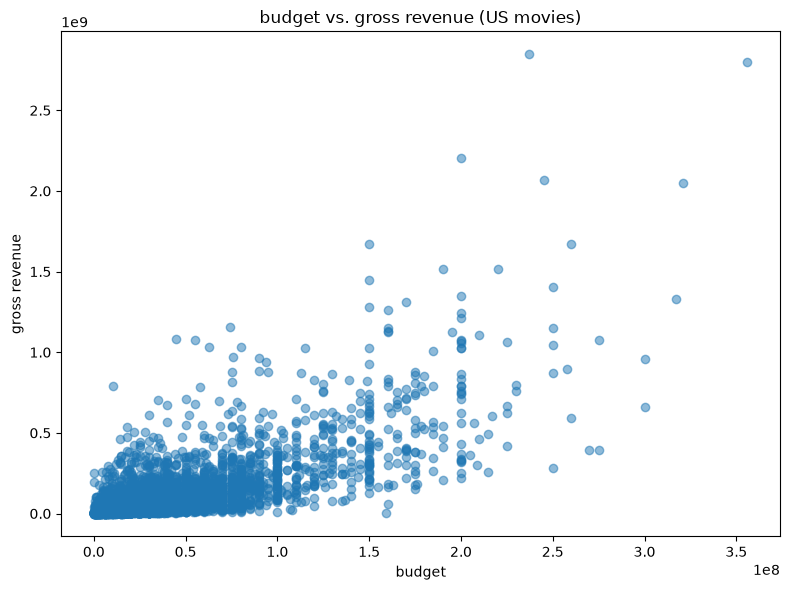

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(us_movies_clean["budget"], us_movies_clean["gross"], alpha=0.5)

plt.title("budget vs. gross revenue (US movies)")
plt.xlabel("budget")
plt.ylabel("gross revenue")

plt.tight_layout()
plt.show()

In [4]:
us_movies_clean["profit ratio"] = us_movies_clean["gross"] / us_movies_clean["budget"]

for i in us_movies_clean.index:
    if us_movies_clean.loc[i, "profit ratio"] >= 2:
        us_movies_clean.loc[i, "success"] = 1
    else:
        us_movies_clean.loc[i, "success"] = 0

us_movies_clean.head()

,name,rating,genre,score,star,budget,gross,company,runtime,profit ratio,success
1,The Blue Lagoon,R,Adventure,5.8,Brooke Shields,4500000.0,58853106.0,Columbia Pictures,104.0,13.078468,1.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,8.7,Mark Hamill,18000000.0,538375067.0,Lucasfilm,124.0,29.909726,1.0
3,Airplane!,PG,Comedy,7.7,Robert Hays,3500000.0,83453539.0,Paramount Pictures,88.0,23.843868,1.0
4,Caddyshack,R,Comedy,7.3,Chevy Chase,6000000.0,39846344.0,Orion Pictures,98.0,6.641057,1.0
5,Friday the 13th,R,Horror,6.4,Betsy Palmer,550000.0,39754601.0,Paramount Pictures,95.0,72.281093,1.0


In [10]:
us_movies_clean_sucess = us_movies_clean[us_movies_clean["success"] == 1.0]

us_movies_clean_failure = us_movies_clean[us_movies_clean["success"] == 0.0]

print("The average runtime of a movie considered a failure is", np.mean(us_movies_clean_failure["runtime"]))

print("The average runtime of a movie considered a sucess is", np.mean(us_movies_clean_sucess["runtime"]))

The average runtime of a movie considered a failure is 106.58405863490609
The average runtime of a movie considered a sucess is 108.10486891385767


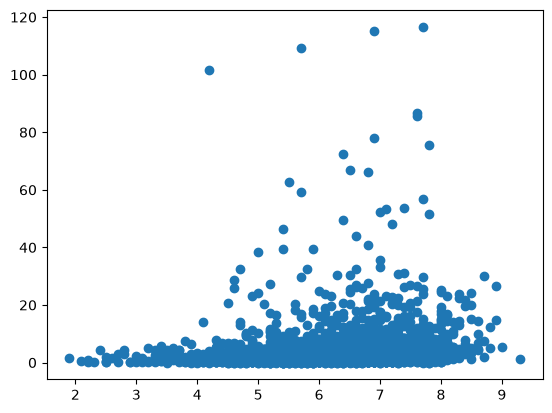

In [15]:
us_movies_clean_remove_profit_ratio_outliers = us_movies_clean[us_movies_clean["profit ratio"] < 200]

plt.scatter(us_movies_clean_remove_profit_ratio_outliers["score"], us_movies_clean_remove_profit_ratio_outliers["profit ratio"])